# Multiple Regression

$$
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k
$$

**Predicted Value:**

$\hat{y}$ = The estimated (or predicted) value of the dependent variable (the outcome) that the model is trying to forecast.

**Intercept:**

$\beta_0$ = The y-intercept or constant term. It's the predicted value of y when all independent variables (x 
1
​
  through x 
k
​
 ) are exactly zero.

**Coefficients:**

$\beta_1 ,\beta_2 x_2 , ..,\beta_k$ = The estimated slope coefficients (or weights). Each βi quantifies the change in  $\hat{y}$ for a one-unit increase in the corresponding xi,holding all other variables constant (the "ceteris paribus" condition).

**Independent Variables:**

$x_1, x_2,...,x_k$ =
The independent variables (features or predictors). These are the input values used to drive the prediction of $\hat{y}$

**Number of Predictors:**

$k$ = The total count of independent variables (features) included in the model, excluding the intercept.


## Assumptions

**Multicollinearity**, is a phenomenon in multiple linear regression where two or more independent variables (predictors or features) in a model are highly correlated with each other.

Imagine trying to determine the individual impact of two ingredients on a cake's flavor, but you always increase them together; it becomes impossible to separate their effects.

**The Impact on the Model**
When you have high multicollinearity, the model can still predict the outcome reasonably well, but the individual coefficients become unstable and unreliable:

1. Unreliable Coefficients: The model doesn't know whether to assign the predictive power to Variable A or Variable B (or split it arbitrarily). Small changes in the data can cause the coefficients (β) to swing wildly, even changing sign (e.g., a variable might suddenly appear to have a negative impact when it should be positive).

2. High Standard Errors: The standard error (σ) of the coefficients increases significantly. This is why, as seen in your last code snippet, collinear variables often end up with a high p-value, making them appear not statistically significant even if the entire model is useful.

## Steps to build the model

**1.Linear Regression model:**  
Calculate the predicted outcome ( 
y^) for a given set of inputs by performing a dot product between the feature vector (x) and the coefficient vector (β).  

In [1]:
from scratch.linear_algebra import dot, Vector

def predict(x: Vector, beta: Vector) -> float:
    """assumes that the first element of x is 1"""
    return dot(x, beta)

**2. Cost Function in LR model**  
Calculate the error (or residual) and the squared error for a single data point. 

In [2]:
from typing import List

def error(x: Vector, y: float, beta: Vector) -> float:
    return predict(x, beta) - y

def squared_error(x: Vector, y: float, beta: Vector) -> float:
    return error(x, y, beta) ** 2

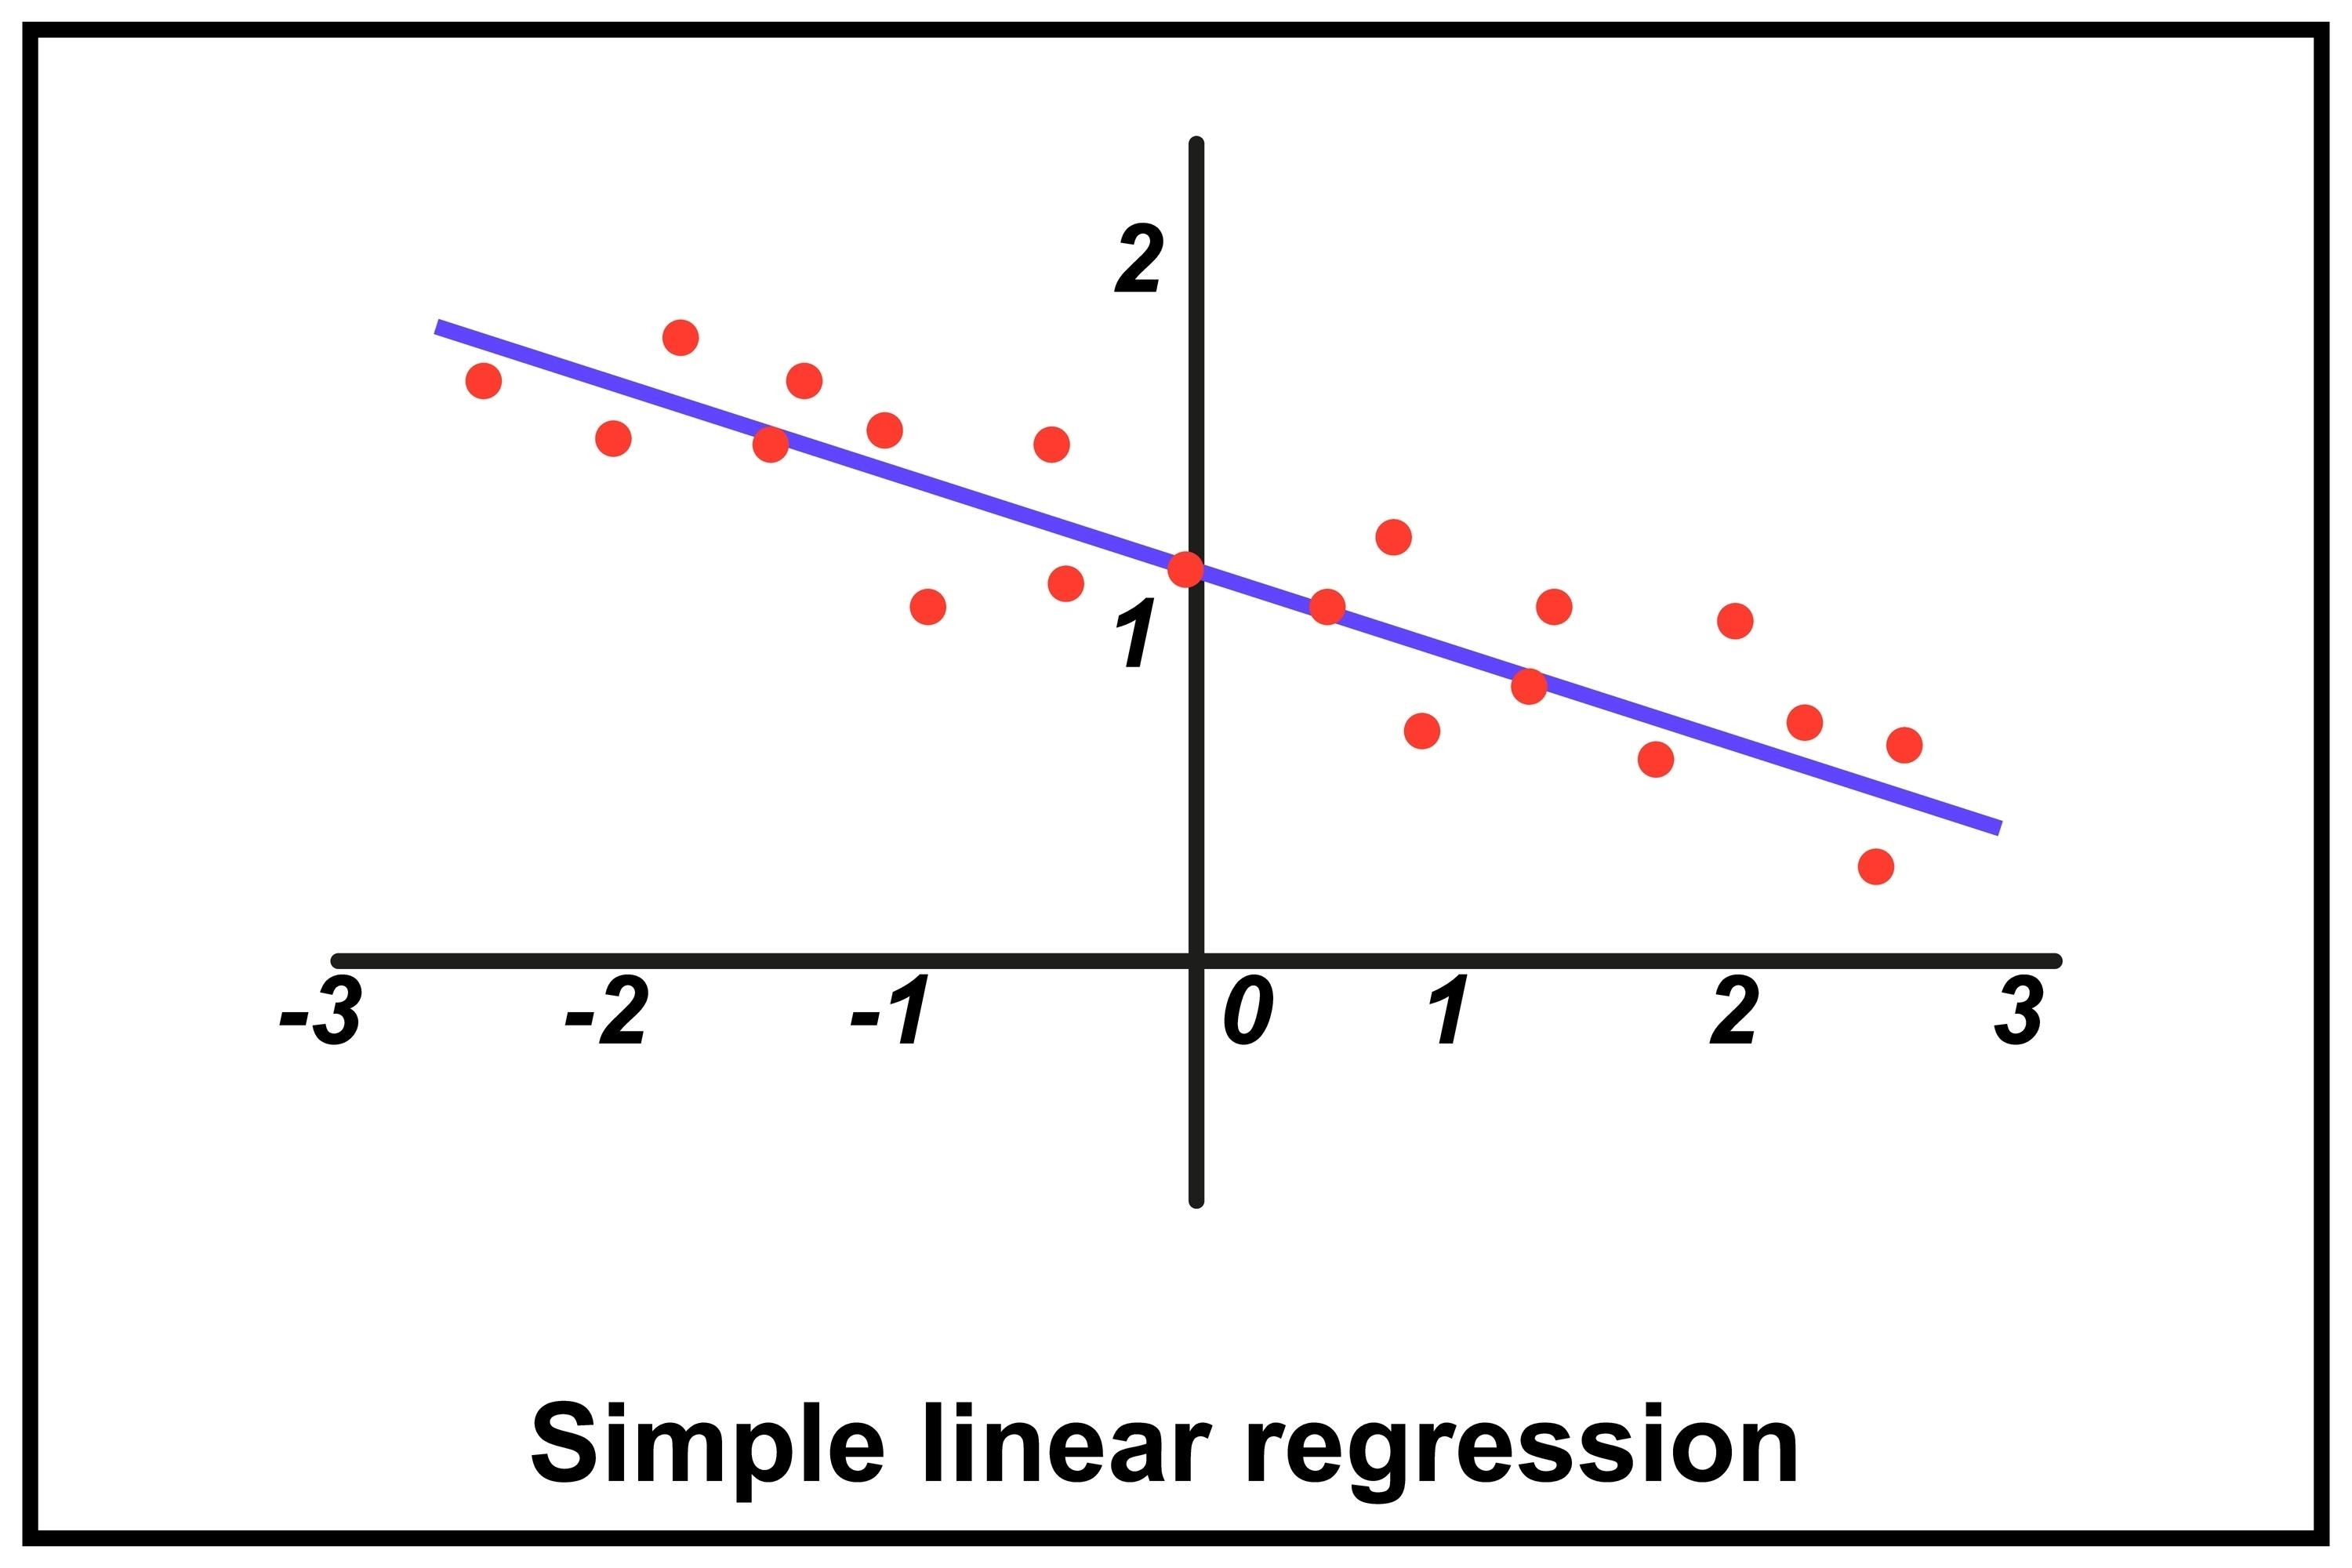

Let´s see an example of how these 2 functions act. **Important**: The first element of vector X should be 1 to use dot function.

In [3]:
x = [1, 2, 3]
y = 30
beta = [4, 4, 4]  # so prediction = 4 + 8 + 12 = 24

assert error(x, y, beta) == -6
assert squared_error(x, y, beta) == 36

**3. Compute the gradient:**  
Calculate the gradient of the cost function with respect to each parameter by taking the partial derivative of the cost function with respect to each parameter.  
The gradient tells you the direction and magnitude of the steepest increase in the error for a single data point. In Gradient Descent, you move in the opposite direction to minimize the error.

In [4]:
def sqerror_gradient(x: Vector, y: float, beta: Vector) -> Vector:
    err = error(x, y, beta)
    return [2 * err * x_i for x_i in x]

assert sqerror_gradient(x, y, beta) == [-12, -24, -36]

**4. Training the model:**  
Find the optimal coefficients (β) that minimize the Sum of Squared Errors (SSE), using the Mini-Batch Gradient Descent algorithm.

The function iteratively refines a starting guess for the coefficients (β) until it converges on the best-fit line.

In [5]:
import random
import tqdm
from scratch.linear_algebra import vector_mean
from scratch.gradient_descent import gradient_step


def least_squares_fit(xs: List[Vector],
                      ys: List[float],
                      learning_rate: float = 0.001,
                      num_steps: int = 1000,
                      batch_size: int = 1) -> Vector:
    """
    Find the beta that minimizes the sum of squared errors
    assuming the model y = dot(x, beta).
    """
    # Start with a random guess
    guess = [random.random() for _ in xs[0]]
    
    #Outer loop: Defines how many times it will repeat the process, in this case it will be 1000
    for _ in tqdm.trange(num_steps, desc="least squares fit"):
    
    #Inner loop: Iterate through batches and modifies the sample in each iteration
        for start in range(0, len(xs), batch_size):
            batch_xs = xs[start:start+batch_size]
            batch_ys = ys[start:start+batch_size]
            
            # Find the average gradient (partial derivative) for each batch of data.Vector_mean returns the average of each gradient for the whole batch
            gradient = vector_mean([sqerror_gradient(x, y, guess) for x, y in zip(batch_xs, batch_ys)])
            
            # Update the parameters for each batch
            guess = gradient_step(guess, gradient, -learning_rate)

    return guess

## Goodness of Fit


The **Multiple R-squared ($\text{R}^2$)** is the primary goodness-of-fit statistic for a multiple linear regression model.

It gives you the **proportion, or percentage, of the total variation in the dependent variable ($Y$) that is explained by all the independent variables ($x_1, x_2, \dots, x_k$) collectively**.

Here are the key takeaways:

* **Range:** $\text{R}^2$ always falls between $\mathbf{0}$ and $\mathbf{1}$.
* **Interpretation:**
    * If **$\text{R}^2 = 0.75$ ($75\%$)**: This means that **$75\%$ of the variability** in the outcome variable ($Y$) is successfully accounted for by the predictors in your model. The remaining $25\%$ is unexplained variation (error).
* **Purpose:** It helps you assess how well your set of predictors describes the data. A higher $\text{R}^2$ generally indicates a better fit.

### ⚠️ A Crucial Caveat: The Problem with $\text{R}^2$

A major limitation of the standard Multiple $\text{R}^2$ is that **it never decreases** when you add a new independent variable to the model, even if that new variable is useless.

For this reason, statisticians often prefer the **Adjusted R-squared**, which penalizes the score for adding unnecessary predictors and provides a more honest measure of model fit.

$\text{R}^2$ can also be expressed as the ratio of **Non Explained Variation ($\text{SSE}$)** to **Total Variation ($\text{SST}$)**:

$$\text{R}^2 = 1-\frac{\text{SSE}}{\text{SST}} = 1- \frac{\sum (\hat{y}_i - y_i)^2}{\sum (y_i - \bar{y})^2}$$

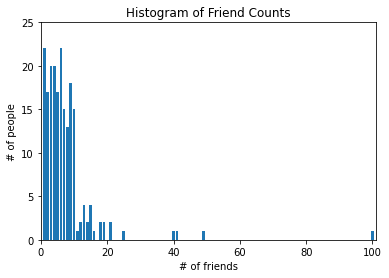

In [6]:
from scratch.simple_linear_regression import total_sum_of_squares

def multiple_r_squared(xs: List[Vector], ys: Vector, beta: Vector) -> float:
    sum_of_squared_errors = sum(error(x, y, beta) ** 2
                                for x, y in zip(xs, ys))
    return 1.0 - sum_of_squared_errors / total_sum_of_squares(ys)

Let´s test the model with real data:

In [7]:
from scratch.statistics import daily_minutes_good
from scratch.statistics import inputs
from scratch.gradient_descent import gradient_step
    
random.seed(0)
    # I used trial and error to choose niters and step_size.
    # This will run for a while.
learning_rate = 0.001
    
beta = least_squares_fit(inputs, daily_minutes_good, learning_rate, 5000, 25)
assert 30.50 < beta[0] < 30.70  # constant
assert  0.96 < beta[1] <  1.00  # num friends
assert -1.89 < beta[2] < -1.85  # work hours per day
assert  0.91 < beta[3] <  0.94  # has PhD
    
assert 0.67 < multiple_r_squared(inputs, daily_minutes_good, beta) < 0.68

print(f""" The parameters for intercept,num friends,work hours per day and PhD are: {beta}""")
print(f""" the R2 of the model is : {multiple_r_squared(inputs, daily_minutes_good, beta)}""")

least squares fit: 100%|██████████| 5000/5000 [00:01<00:00, 2546.07it/s]

 The parameters for intercept,num friends,work hours per day and PhD are: [30.514795945185586, 0.9748274277323267, -1.8506912934343662, 0.91407780744768]
 the R2 of the model is : 0.6799849346187969


## The Bootstrap

The intention of the Bootstrap in Multiple Regression is to estimate the uncertainty and stability of the model's coefficients (β) without relying on strong theoretical assumptions about the data's distribution (like Normality).  
The bootstrap works by treating the original sample as the population and performing the following steps thousands of times:

**Resample:** Draw a new sample of (x,y) pairs with replacement that is the same size as the original dataset.

**Re-fit:** Re-estimate all the regression coefficients (β) using this new resampled dataset.

**Analyze:** The collection of thousands of resulting coefficient vectors forms the empirical sampling distribution, which is used to derive the SEs and CIs.

In [8]:
from typing import TypeVar, Callable

X = TypeVar('X')        # Generic type for data
Stat = TypeVar('Stat')  # Generic type for "statistic"

def bootstrap_sample(data: List[X]) -> List[X]:
    """randomly samples len(data) elements with replacement"""
    return [random.choice(data) for _ in data]

def bootstrap_statistic(data: List[X],
                        stats_fn: Callable[[List[X]], Stat],
                        num_samples: int) -> List[Stat]:
    """evaluates stats_fn on num_samples bootstrap samples from data"""
    # Builds a list (the empirical sampling distribution) containing the statistic calculated from each of the bootstrap samples.
    return [stats_fn(bootstrap_sample(data)) for _ in range(num_samples)]




Let´s see an example where the median of 2 samples are the same (close to 100) but when doing bootstrap, we realise that the standard deviations are very different.  
the code uses the bootstrap to empirically compare the Standard Error (measured by the standard deviation of the bootstrap samples) of the median statistic under two very different data distributions.

In [9]:
# 101 points all very close to 100
close_to_100 = [99.5 + random.random() for _ in range(101)]

# 101 points, 50 of them near 0, 50 of them near 200
far_from_100 = ([99.5 + random.random()] +
                [random.random() for _ in range(50)] +
                [200 + random.random() for _ in range(50)])

In [10]:
from scratch.statistics import median, standard_deviation,mean

medians_close = bootstrap_statistic(close_to_100, median, 100)

medians_far = bootstrap_statistic(far_from_100, median, 100)

assert standard_deviation(medians_close) < 1
assert standard_deviation(medians_far) > 90


Now let´s estimate how much the coefficients (β) of the linear regression model would vary if the analysis were repeated on different random samples from the same population. 

In [11]:
 from typing import Tuple
    
import datetime
    
def estimate_sample_beta(pairs: List[Tuple[Vector, float]]):
        x_sample = [x for x, _ in pairs]
        y_sample = [y for _, y in pairs]
        beta = least_squares_fit(x_sample, y_sample, learning_rate, 5000, 25)
        print("bootstrap sample", beta)
        return beta
    
random.seed(0) # so that you get the same results
    
#Take random samples using pair of inputs and daily_minutes_good to recalculate beta 10 times
bootstrap_betas = bootstrap_statistic(list(zip(inputs, daily_minutes_good)),estimate_sample_beta,100)

#Find the standard deviation of each Beta in the list of bootstrap_betas
bootstrap_standard_errors = [standard_deviation([beta[i] for beta in bootstrap_betas]) for i in range(4)]
bootstrap_mean = [mean([beta[i] for beta in bootstrap_betas]) for i in range(4)]


print(f""" The mean of each parameter is: {bootstrap_mean}""")    
print(f""" The standar deviation of each parameter is: {bootstrap_standard_errors}""")
    
    # [1.272,    # constant term, actual error = 1.19
    #  0.103,    # num_friends,   actual error = 0.080
    #  0.155,    # work_hours,    actual error = 0.127
    #  1.249]    # phd,           actual error = 0.998

least squares fit: 100%|██████████| 5000/5000 [00:01<00:00, 2505.36it/s]


bootstrap sample [30.49402029547432, 1.0393791030498776, -1.9516851948558502, 0.7483721251697333]


least squares fit: 100%|██████████| 5000/5000 [00:01<00:00, 2528.47it/s]


bootstrap sample [30.149963287526045, 1.0005300432763113, -2.0650380122822543, 3.177179854834797]


least squares fit: 100%|██████████| 5000/5000 [00:01<00:00, 2541.20it/s]


...

bootstrap sample [31.725525991297584, 0.8939775539447468, -1.843559060469148, -0.6224324630864045]


least squares fit: 100%|██████████| 5000/5000 [00:01<00:00, 2504.85it/s]


bootstrap sample [30.2731194689144, 0.8005769229528958, -1.6991234036996576, 0.9748341305369917]


least squares fit: 100%|██████████| 5000/5000 [00:01<00:00, 2502.10it/s]

bootstrap sample [31.75696506368952, 1.0790800487199688, -2.0880894078200054, 1.6420943383461737]
 The mean of each parameter is: [30.5563190684443, 0.9869446479023908, -1.8666713368416388, 0.9517571483014551]
 The standar deviation of each parameter is: [1.2715078186272781, 0.10318410116073963, 0.15510591689663628, 1.2490975248051257]


¿How can we use this information to validate the model ?

In [12]:
from scipy.stats import norm
import numpy as np

def p_value_scipy(beta_hat_j: float, sigma_hat_j: float) -> float:
    # Calcular el estadístico Z (o T)
    z_score = beta_hat_j / sigma_hat_j
    p_value = 2 * norm.sf(np.abs(z_score))
    
    return p_value


p_val_num_friends = p_value_scipy(bootstrap_mean[1], bootstrap_standard_errors[1])
p_val_work_hours = p_value_scipy(bootstrap_mean[2], bootstrap_standard_errors[2])
p_val_phd = p_value_scipy(bootstrap_mean[3], bootstrap_standard_errors[3])

print(f"P-value para num_friends: {p_val_num_friends:.3f}")
print(f"P-value para work_hours: {p_val_work_hours:.3f}")
print(f"P-value para phd: {p_val_phd:.3f}")

P-value para num_friends: 0.000
P-value para work_hours: 0.000
P-value para phd: 0.446


As p-value of phd variable is above 0.05%, it means that probably is no that relevant in our model

##  Practical Case: Modeling House Prices

Next, you'll find the data on house prices. Our working hypothesis is that the **Area**, the **Number of Rooms**, and the **Age** of the property **significantly impact** its **Sale Price ($Y$)**.

Your job is to find the regression model that best fits this data and evaluate whether the variables used have a statistically significant effect.

---

### 1. The Data (Input $\mathbf{X}$ and Output $Y$)

Use the following lists to fit the model $\hat{Y} = \hat{\beta}_0 + \hat{\beta}_1 X_1 + \hat{\beta}_2 X_2 + \hat{\beta}_3 X_3$.

|List|Meaning|
|:---|:---|
|$Y$|Sale Price (Thousands of USD)|
|$X$|Predictor Variables (1, Area, Rooms, Age)|


In [13]:
y=[255,180,310,220,450,280,195,350,235,410,165,375,300,210,330]
x = [
    [1, 160, 3, 5],
    [1, 100, 2, 15],
    [1, 185, 4, 2],
    [1, 130, 3, 10],
    [1, 250, 5, 1],
    [1, 170, 3, 8],
    [1, 115, 2, 12],
    [1, 200, 4, 3],
    [1, 140, 3, 7],
    [1, 220, 4, 4],
    [1, 90, 2, 18],
    [1, 210, 4, 2],
    [1, 175, 3, 6],
    [1, 125, 2, 11],
    [1, 190, 4, 4]
]